# 06 · Pronóstico de la lista de tendencias (exploratorio)

**Proyecto:** videos en tendencia de YouTube en Estados Unidos
**Metodología:** CRISP-DM, etapas 4 (modelado) y 5 (evaluación)

Los notebooks anteriores predicen el resultado de **un video**. Este responde una pregunta distinta, sobre el **tiempo**: ¿cuántas vistas tendrá el video típico de la lista de tendencias en las próximas dos semanas? Esa cifra es la vara que un video debe alcanzar para estar en la lista, y sirve como referencia para fijar metas.

**Es un ejercicio exploratorio.** La serie tiene solo 213 días, ocho de ellos sin datos, y un cambio de comportamiento en marzo de 2018. Se incluye para mostrar qué se puede pronosticar con estos datos y con qué margen de error.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

sys.path.append(str(Path.cwd().parent))
from src.data import FIGURES_DIR, PROCESSED_DIR
from src.viz import BLUE, COMPACT, INK_SECONDARY, PALETTE, set_style

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

daily = pd.read_parquet(PROCESSED_DIR / "daily.parquet")

## 1. Construcción de la serie

Para cada día se toma la **mediana de vistas de los 200 videos de la lista**. Se trabaja en logaritmo, porque la serie crece de forma multiplicativa. Los ocho días sin datos se completan por interpolación lineal: los modelos de series de tiempo necesitan una serie sin huecos, y son pocos días frente al total.

Días: 213 · días interpolados: 8


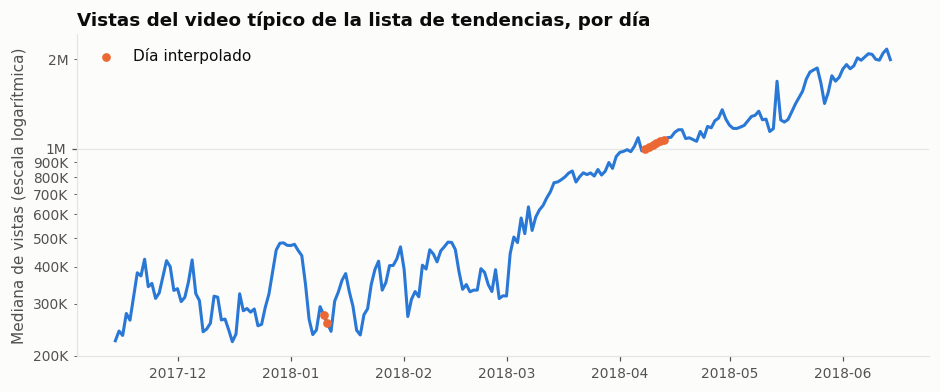

In [2]:
calendar = pd.date_range(daily["trending_date"].min(), daily["trending_date"].max(), freq="D")
median_views = daily.groupby("trending_date")["views"].median().reindex(calendar)
missing = median_views.isna()
series = np.log(median_views).interpolate()

print(f"Días: {len(series)} · días interpolados: {missing.sum()}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(series.index, np.exp(series), color=BLUE)
ax.scatter(series.index[missing], np.exp(series[missing]), s=22, color=PALETTE[1], zorder=3, label="Día interpolado")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(COMPACT)
ax.yaxis.set_minor_formatter(COMPACT)
ax.set_title("Vistas del video típico de la lista de tendencias, por día")
ax.set_ylabel("Mediana de vistas (escala logarítmica)")
ax.legend(loc="upper left")
fig.savefig(FIGURES_DIR / "06_serie_diaria.png")
plt.show()

In [3]:
weekly = (series - series.rolling(7, center=True).mean()).groupby(series.index.dayofweek).mean()
weekly.index = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
(np.exp(weekly) - 1).mul(100).rename("Diferencia frente a la media semanal (%)").to_frame().T

,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
Diferencia frente a la media semanal (%),2.941,4.033,3.696,1.175,-2.213,-4.910,-3.662


**Lo que muestra la serie:**

- **Estable hasta febrero** (cerca de 300 mil vistas) y **creciente desde marzo**, hasta cerca de 2 millones a mediados de junio. Es el cambio de comportamiento descrito en el notebook 03.
- **Patrón semanal leve:** la lista tiene entre 3% y 4% más vistas de lunes a miércoles y 5% menos el sábado.
- No hay estacionalidad anual que estimar con siete meses.

## 2. Modelos candidatos

| Modelo | Qué supone |
|---|---|
| **Ingenuo** | Mañana será igual que hoy. Es la referencia mínima. |
| **Ingenuo estacional** | Cada día será igual al mismo día de la semana anterior. |
| **Con deriva** | Continúa la tendencia de las últimas cuatro semanas. |
| **Holt-Winters** | Suavizado exponencial con tendencia amortiguada y patrón semanal. |
| **SARIMA (1,1,1)(0,1,1)₇** | Modela los cambios de un día a otro y el patrón semanal. |

Los tres primeros no son modelos estadísticos: son reglas. Se incluyen porque un modelo de pronóstico solo se justifica si las supera.

In [4]:
HORIZON = 14


def forecasts(train, horizon=HORIZON):
    last = train.iloc[-1]
    steps = np.arange(1, horizon + 1)
    return {
        "Ingenuo": np.full(horizon, last),
        "Ingenuo estacional": np.array([train.iloc[-7 + (i % 7)] for i in range(horizon)]),
        "Con deriva": last + steps * (last - train.iloc[-29]) / 28,
        "Holt-Winters": ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add",
                                             seasonal_periods=7).fit().forecast(horizon).to_numpy(),
        "SARIMA": SARIMAX(train, order=(1, 1, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=0)
        .forecast(horizon).to_numpy(),
    }

## 3. Evaluación: validación con origen móvil

Un solo corte de entrenamiento y prueba diría poco en una serie tan corta. Se usa **validación con origen móvil**: se entrena con los primeros 120 días y se pronostican los 14 siguientes; luego se avanza una semana y se repite. Son 12 pronósticos, cada uno comparado con lo que ocurrió en realidad.

La métrica es el error absoluto medio en logaritmo, que se traduce a un **error porcentual típico**.

In [5]:
errors, by_step = {}, {}
origins = list(range(120, len(series) - HORIZON + 1, 7))
for origin in origins:
    train, actual = series.iloc[:origin], series.iloc[origin:origin + HORIZON].to_numpy()
    for name, predicted in forecasts(train).items():
        absolute = np.abs(predicted - actual)
        errors.setdefault(name, []).append(absolute.mean())
        by_step.setdefault(name, []).append(absolute)

results = pd.DataFrame({
    "Error absoluto medio (log)": {k: np.mean(v) for k, v in errors.items()},
    "Error típico (%)": {k: (np.exp(np.mean(v)) - 1) * 100 for k, v in errors.items()},
    "Veces que fue el mejor": pd.DataFrame(errors).idxmin(axis=1).value_counts(),
}).fillna(0).sort_values("Error absoluto medio (log)")
results["Veces que fue el mejor"] = results["Veces que fue el mejor"].astype(int)
print(f"Pronósticos evaluados: {len(origins)} · horizonte: {HORIZON} días")
results

Pronósticos evaluados: 12 · horizonte: 14 días


,Error absoluto medio (log),Error típico (%),Veces que fue el mejor
SARIMA,0.074,7.727,5
Con deriva,0.087,9.043,4
Ingenuo,0.108,11.390,3
Holt-Winters,0.144,15.441,0
Ingenuo estacional,0.144,15.445,0


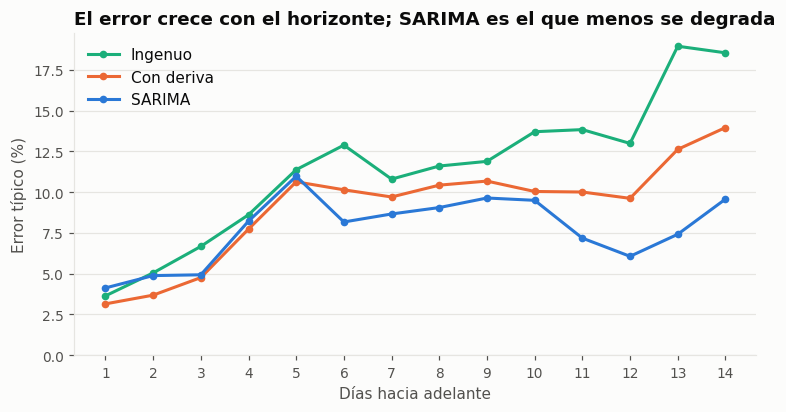

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, color in [("Ingenuo", PALETTE[2]), ("Con deriva", PALETTE[1]), ("SARIMA", BLUE)]:
    curve = (np.exp(np.mean(by_step[name], axis=0)) - 1) * 100
    ax.plot(range(1, HORIZON + 1), curve, color=color, marker="o", markersize=4, label=name)
ax.set_title("El error crece con el horizonte; SARIMA es el que menos se degrada")
ax.set_xlabel("Días hacia adelante")
ax.set_ylabel("Error típico (%)")
ax.set_xticks(range(1, HORIZON + 1))
ax.set_ylim(0)
ax.legend(loc="upper left")
fig.savefig(FIGURES_DIR / "06_error_por_horizonte.png")
plt.show()

**Lectura:**

- **SARIMA es el mejor:** se equivoca en promedio un 7,7% a 14 días, frente al 11,4% de la regla ingenua. Fue el mejor en 5 de los 12 pronósticos.
- **La ventaja es moderada.** La regla "con deriva", que solo prolonga la tendencia reciente, queda cerca (9,0%) y gana en 4 de 12. Buena parte de lo que SARIMA aporta es seguir la tendencia.
- **Holt-Winters y el ingenuo estacional son peores que no hacer nada** (15,4%). El patrón semanal es demasiado leve frente al crecimiento de la serie, y apoyarse en él perjudica.
- **El error crece con el horizonte:** el pronóstico a pocos días es mucho más confiable que el de dos semanas.

**Modelo elegido: SARIMA**, por tener el menor error y degradarse menos con el horizonte.

## 4. Pronóstico de los 14 días siguientes

Se reentrena el SARIMA con toda la serie y se pronostican los 14 días posteriores al último dato (15 al 28 de junio de 2018), con su intervalo de confianza del 80%.

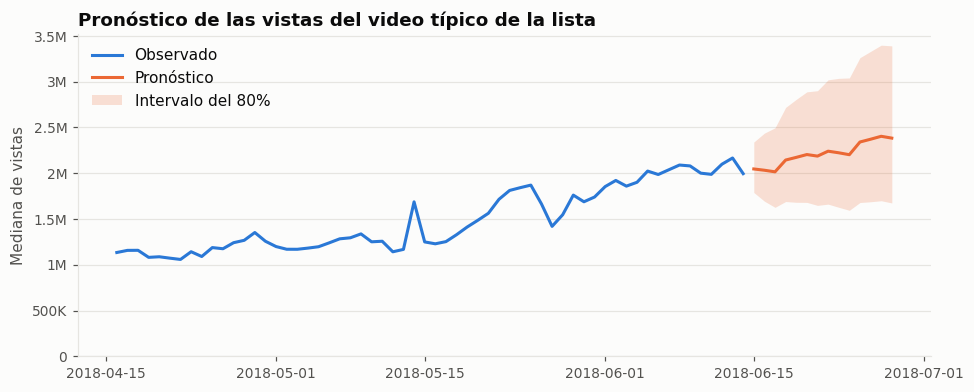

,Pronóstico,Límite inferior (80%),Límite superior (80%)
2018-06-15 00:00:00,"2,046,584","1,789,538","2,340,552"
2018-06-21 00:00:00,"2,187,094","1,648,634","2,901,421"
2018-06-28 00:00:00,"2,383,625","1,675,440","3,391,151"


In [7]:
model = SARIMAX(series, order=(1, 1, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=0)
prediction = model.get_forecast(HORIZON)
interval = prediction.conf_int(alpha=0.2)
forecast = pd.DataFrame({
    "Pronóstico": np.exp(prediction.predicted_mean),
    "Límite inferior (80%)": np.exp(interval.iloc[:, 0]),
    "Límite superior (80%)": np.exp(interval.iloc[:, 1]),
})

recent = np.exp(series.iloc[-60:])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(recent.index, recent, color=BLUE, label="Observado")
ax.plot(forecast.index, forecast["Pronóstico"], color=PALETTE[1], label="Pronóstico")
ax.fill_between(forecast.index, forecast["Límite inferior (80%)"], forecast["Límite superior (80%)"],
                color=PALETTE[1], alpha=0.2, linewidth=0, label="Intervalo del 80%")
ax.yaxis.set_major_formatter(COMPACT)
ax.set_ylim(0)
ax.set_title("Pronóstico de las vistas del video típico de la lista")
ax.set_ylabel("Mediana de vistas")
ax.legend(loc="upper left")
fig.savefig(FIGURES_DIR / "06_pronostico.png")
plt.show()

forecast.iloc[[0, 6, 13]].style.format("{:,.0f}")

**Lectura:** el modelo proyecta que la vara de la lista seguiría subiendo, de cerca de 2,0 millones de vistas a unos 2,4 millones dos semanas después. El intervalo se abre rápido: a 14 días va de 1,7 a 3,4 millones.

**Advertencia importante:** el pronóstico prolonga el crecimiento observado desde marzo. Ese crecimiento parece venir de un cambio en la plataforma, y nada garantiza que continúe; ningún modelo de series de tiempo puede anticipar el siguiente cambio de reglas. Por eso este pronóstico solo es razonable a muy corto plazo.

## 5. Conclusiones

- **Sí se puede pronosticar el nivel de la lista de tendencias a corto plazo**, con un error típico de 7,7% a 14 días usando SARIMA, mejor que las reglas simples.
- **El valor práctico es limitado.** Sirve como referencia de corto plazo para fijar metas ("para estar en la lista hoy hacen falta cerca de 2 millones de vistas"), no para planear a meses.
- **La serie es demasiado corta e inestable para más:** siete meses, sin estacionalidad anual medible y con un cambio estructural en marzo de 2018. Con dos o tres años de datos se podría estimar estacionalidad anual y evaluar el modelo con más rigor.
- Este notebook complementa a los anteriores, que siguen siendo el núcleo del análisis: las decisiones de la empresa dependen más de qué y con quién publicar (notebooks 03 a 05) que del nivel general de la lista.